# SentimentScope: Sentiment Analysis with Transformers

A custom PyTorch transformer trained from scratch to classify IMDb movie reviews as positive or negative. The project uses the pretrained `bert-base-uncased` **tokenizer**, not pretrained BERT model weights.

The saved run achieved **77.58% test accuracy** and **80.76% final validation accuracy** after five epochs. Outputs below come from the original training run; formatting cleanup did not retrain the model.

## Project outline

1. [Dataset exploration and preparation](#load-explore-and-prepare-the-dataset)
2. [PyTorch datasets and data loaders](#implement-a-dataloader-in-pytorch)
3. [Transformer architecture](#customize-the-transformer-architecture)
4. [Accuracy calculation](#implement-accuracy-calculation-method)
5. [Training](#train-the-model)
6. [Test evaluation](#test-the-model)
7. [Results and takeaways](#conclusion)

## Data and setup

The [Stanford Large Movie Review Dataset](https://ai.stanford.edu/~amaas/data/sentiment/) contains 25,000 labeled training reviews and 25,000 labeled test reviews. Labels are **0 = negative** and **1 = positive**. Unlabeled reviews are not used.

Install the dependencies in `requirements.txt`, download `aclImdb_v1.tar.gz` from the dataset page, and place it beside this notebook. Run the cells in order. A CUDA GPU is recommended for training; the notebook falls back to CPU.

This project was completed as part of the Udacity Future AWS AI Programmer Nanodegree and adapted from its project starter notebook.


## Dataset exploration and preparation <a id="load-explore-and-prepare-the-dataset"></a>

### Load the dataset

Extract the downloaded archive into the current directory.


In [1]:
import os
import pandas as pd


In [2]:
# Extract the downloaded dataset
!tar -xzf aclImdb_v1.tar.gz


The labeled reviews are stored in `train/pos`, `train/neg`, `test/pos`, and `test/neg` under `aclImdb/`.


In [3]:
# Define paths to dataset
train_pos_path = "aclImdb/train/pos"  # Path to the directory containing positive reviews from the training set
train_neg_path = "aclImdb/train/neg"  # Path to the directory containing negative reviews from the training set
test_pos_path = "aclImdb/test/pos"  # Path to the directory containing positive reviews from the test set
test_neg_path = "aclImdb/test/neg"  # Path to the directory containing negative reviews from the test set


`load_dataset` reads UTF-8 text files in sorted filename order, returning one string per review.


In [4]:
def load_dataset(folder):
    """
    Reads all text files in the specified folder and returns their content as a list.

    Args:
        folder (str): Path to the folder containing text files.

    Returns:
        list: A list of strings, where each string is the content of a text file.
    """
    reviews = []
    all_files = sorted(os.listdir(folder))
    for filename in all_files:
        file_path = os.path.join(folder, filename)
        if filename.lower().endswith(".txt") and os.path.isfile(file_path):
            with open(file_path, "r", encoding="utf-8") as file:
                reviews.append(file.read())

    return reviews


Load the positive and negative reviews for each split.


In [5]:
# Load training and testing data
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)


Combine reviews and binary sentiment labels into pandas DataFrames.


In [6]:
# Create DataFrames
train_df = pd.DataFrame(
    {
        "review": train_pos + train_neg,
        "label": [1] * len(train_pos) + [0] * len(train_neg),
    }
)

test_df = pd.DataFrame(
    {"review": test_pos + test_neg, "label": [1] * len(test_pos) + [0] * len(test_neg)}
)

print(train_df.head())


                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1


Check that both splits contain 25,000 rows and the expected two columns.


In [7]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."


### Explore the dataset

Inspect schema, descriptive statistics, missing values, duplicate reviews, sentiment balance, review lengths, and sample reviews.


In [8]:
import matplotlib.pyplot as plt

datasets = {"Training": train_df, "Testing": test_df}
sentiments = {0: "Negative", 1: "Positive"}
palette = ["#E8998D", "#69B3A2"]

# 1. Dataset Overview
for dataset_name, data in datasets.items():
    print(f"{dataset_name.upper()} DATASET\n")
    data.info()

    print("\nGenerating descriptive statistics:")
    print(data.describe(include="all"))

    print("\nMissing values per column:")
    print(data.isna().sum())

    repeated_reviews = data["review"].duplicated().sum()
    print(f"\nRepeated reviews: {repeated_reviews:}\n")


TRAINING DATASET

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

Generating descriptive statistics:
                                                   review        label
count                                               25000  25000.00000
unique                                              24904          NaN
top     You do realize that you've been watching the E...          NaN
freq                                                    3          NaN
mean                                                  NaN      0.50000
std                                                   NaN      0.50001
min                                                   NaN      0.00000
25%                                                   NaN      0.00000
50%

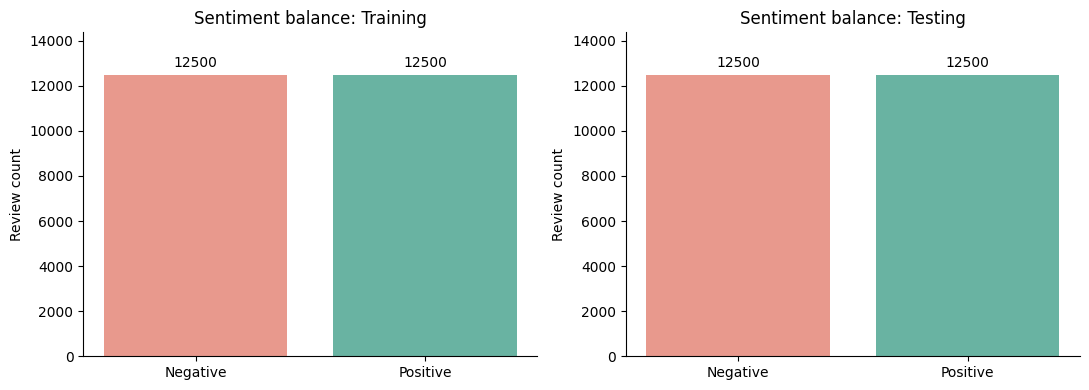

In [9]:
# 2. Label Distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for axis, (dataset_name, data) in zip(axes, datasets.items()):
    totals = data["label"].value_counts().reindex([0, 1], fill_value=0)

    bars = axis.bar(sentiments.values(), totals.values, color=palette)
    axis.bar_label(bars, padding=3)
    axis.set_title(f"Sentiment balance: {dataset_name}")
    axis.set_ylabel("Review count")
    axis.margins(y=0.15)
    axis.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()



Training: review length summary
       characters    words
count     25000.0  25000.0
mean       1325.1    233.8
std        1003.1    173.7
min          52.0     10.0
25%         702.0    127.0
50%         979.0    174.0
75%        1614.0    284.0
max       13704.0   2470.0

Testing: review length summary
       characters    words
count     25000.0  25000.0
mean       1293.8    228.5
std         975.9    168.9
min          32.0      4.0
25%         696.0    126.0
50%         962.0    172.0
75%        1572.0    277.0
max       12988.0   2278.0


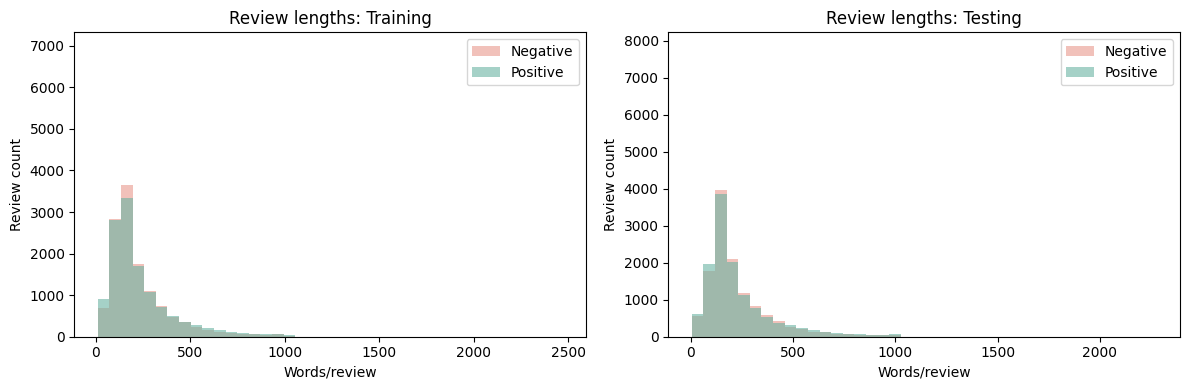

In [10]:
# 3. Review Length Analysis
length_tables = {}

for dataset_name, data in datasets.items():
    lengths = data[["label"]].copy()
    lengths["characters"] = data["review"].str.len()
    lengths["words"] = data["review"].str.split().str.len()
    length_tables[dataset_name] = lengths

    print(f"\n{dataset_name}: review length summary")
    print(lengths[["characters", "words"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for axis, (dataset_name, lengths) in zip(axes, length_tables.items()):
    word_counts = lengths["words"].dropna()
    if word_counts.empty:
        axis.set_title(f"{dataset_name}: no review lengths available")
        continue

    _, bin_edges, _ = axis.hist(word_counts, bins=40, visible=False)

    for (label, sentiment), color in zip(sentiments.items(), palette):
        values = lengths.loc[lengths["label"] == label, "words"].dropna()
        axis.hist(values, bins=bin_edges, alpha=0.6, color=color, label=sentiment)

    axis.set_title(f"Review lengths: {dataset_name}")
    axis.set_xlabel("Words/review")
    axis.set_ylabel("Review count")
    axis.legend()

plt.tight_layout()
plt.show()


In [11]:
# 4. Sample Reviews
for label, sentiment in sentiments.items():
    candidates = train_df.loc[train_df["label"].eq(label), "review"].dropna()

    examples = candidates.sample(n=min(2, len(candidates)), random_state=17)

    print(f"\n{sentiment.upper()} REVIEW")
    for number, text in enumerate(examples, start=1):
        print(f"\nReview {number} ({len(text.split())} words):\n{text}")



NEGATIVE REVIEW

Review 1 (210 words):
The Hills Have Eyes II is what you would expect it to be and nothing more. Of course it's not going to be an Oscar nominated film, it's just pure entertainment which you can just lose yourself in for 90 minutes.<br /><br />The plot is basically about a group of National Guard trainees who find themselves battling against the notorious mutated hillbillies on their last day of training in the desert. It's just them fighting back throughout the whole film, which includes a lot of violence (which is basically the whole film) as blood and guts are constantly flying around throughout the whole thing, and also yet another graphic rape scene which is pointlessly thrown in to shock the audience.<br /><br />I'd give the Hills Have Eyes II 4 out of 10 for pure entertainment, and that only. Although even then I found myself looking at my watch more and more as the film went on, as it began to drag due to the fact it continued to try and shock the audience wi

### Prepare the dataset

Shuffle the labeled training data with a fixed split seed, then reserve 10% for validation: 22,500 training reviews and 2,500 validation reviews. Keep the 25,000 test reviews separate.


In [12]:
# Split train data into training and validation sets manually
train_size = int(0.9 * len(train_df))
# Shuffle the dataset
shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
train_data = shuffled_df.iloc[:train_size]
val_data = shuffled_df.iloc[train_size:]


### Tokenization

Use Hugging Face’s `bert-base-uncased` subword tokenizer. Reviews are truncated or padded to 128 tokens. The classifier itself is initialized randomly and trained from scratch.


In [13]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")


Inspect tokenization on three sampled training reviews.


In [14]:
# Take sample inputs from the dataset
sample_texts = train_data["review"].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(
    sample_texts,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt",
)


In [15]:
print(tokenized_samples)


{'input_ids': tensor([[  101,  2348,  1996,  3185,  2003,  4415,  6052,  1010,  9501,  2064,
          2145,  4089,  6709,  2007,  1996, 24525,  1997,  5292, 21112,  2015,
         18396,  1999,  2023, 27768,  1998,  2200,  6057,  2104, 16168,  6925,
          1012, 18396,  9590,  2114,  4895, 18824,  2135, 10238,  1999,  2093,
          2367,  5535,  1024,  1996,  2962,  2287,  1010,  1996,  3142,  2287,
          1010,  1998,  1996,  5549,  2078,  2287,  1010,  2652,  2471,  1996,
          2168,  2839,  2007,  2074,  1037,  2689,  1997, 17363,  2000,  2393,
          2149,  6709,  1996,  2367,  1000,  5535,  1000,  1012,  1999,  2023,
          3185,  2057,  2156,  2028,  1997,  1996,  5700, 21699, 20818,  1997,
          1996,  1000,  5430,  2386,  1000, 12991, 13874,  1010,  2040,  5222,
          2010,  2293,  2025,  2011,  7472,  2021,  2011, 26128,  2486,  1010,
          2004,  2092,  2004,  1037,  6057,  9792,  2006,  3142,  5580,  2401,
         29469,  2389,  4337,  1010,  

`truncation=True` limits each review to `max_length=128`. `padding="max_length"` gives all inputs the same length, and `return_tensors="pt"` returns PyTorch tensors.


## PyTorch datasets and data loaders <a id="implement-a-dataloader-in-pytorch"></a>

### Custom dataset

`IMDBDataset` tokenizes each review on access and returns its token IDs and integer sentiment label.


In [16]:
import torch
from torch.utils.data import Dataset

MAX_LENGTH = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


Inputs are limited to 128 tokens. CUDA is used when available; training on CPU is slower.


In [17]:
from torch.utils.data import Dataset

max_length = 128


class IMDBDataset(Dataset):
    """
    A custom PyTorch Dataset for the IMDB dataset.

    This class preprocesses text data using a tokenizer and returns tokenized inputs
    along with their corresponding labels for sentiment analysis.

    Attributes:
        data (pd.DataFrame): A DataFrame containing text and label columns.
        tokenizer (transformers.PreTrainedTokenizer): The tokenizer used for preprocessing text.
        max_length (int): Maximum length for tokenized sequences.
    """

    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        """
        Initialize the dataset.

        Args:
            data (pd.DataFrame): A DataFrame with columns `review` (text) and `label` (target).
            tokenizer (transformers.PreTrainedTokenizer): The tokenizer to preprocess the text.
            max_length (int, optional): Maximum token sequence length. Defaults to 128.
        """
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        """
        Return the total number of samples in the dataset.

        Returns:
            int: Number of samples.
        """
        return len(self.data)

    def __getitem__(self, idx):
        """
        Retrieve a single data point by index and preprocess it.

        Args:
            idx (int): Index of the data point to retrieve.

        Returns:
            torch.Tensor: Tokenized input IDs for the text.
            int: Label corresponding to the text.
        """
        text = self.data.iloc[idx]["review"]
        label = int(self.data.iloc[idx]["label"])
        inputs = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        )
        return inputs["input_ids"].squeeze(0), label


### Initialize the datasets

Create datasets for the training, validation, and test splits.


In [18]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)


### Create data loaders

Training uses shuffled batches of 64 reviews. Validation and test loaders preserve their input order.


In [19]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 64

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


Each epoch processes the training dataset once. The assertions below check split sizes, label types, and token sequence length.


In [20]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, (
    "Input IDs tensor has incorrect length!"
)


## Transformer architecture <a id="customize-the-transformer-architecture"></a>

### Configuration

The model uses 384-dimensional embeddings, six transformer blocks, eight attention heads, and a 128-token context window.


In [21]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,  # binary classification (pos/neg)
    "d_embed": 384,
    "context_size": MAX_LENGTH,
    "layers_num": 6,
    "heads_num": 8,
    "head_size": 48,  # 8 heads * 48 = 384 -> matches d_embed
    "dropout_rate": 0.2,
    "use_bias": True,
    "pad_token_id": tokenizer.pad_token_id,
}


Key Config Parameters:
- `vocabulary_size`: The total number of tokens in your vocabulary.
- `num_classes`: The number of classes for the classification head (2 = binary).
- `d_embed`: Dimensionality of embeddings (and hidden layers).
- `context_size`: Maximum sequence length for each input.
- `layers_num`: Number of stacked transformer blocks.
- `heads_num`: Number of attention heads in multi-head attention.
- `head_size`: Dimension of each attention head (must satisfy heads_num * head_size = d_embed).
- `dropout_rate`: Probability of dropping units during training to reduce overfitting.
- `use_bias`: Whether linear layers should have bias terms.


### Attention head

Each head computes scaled dot-product attention with a causal mask and dropout.


In [22]:
import torch.nn as nn
import math


class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(
            config["d_embed"], config["head_size"], bias=config["use_bias"]
        )
        self.K_weights = nn.Linear(
            config["d_embed"], config["head_size"], bias=config["use_bias"]
        )
        self.V_weights = nn.Linear(
            config["d_embed"], config["head_size"], bias=config["use_bias"]
        )

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(
            torch.ones(config["context_size"], config["context_size"])
        )
        self.register_buffer("casual_attention_mask", casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Causal mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0, float("-inf")
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V


Check one attention head using a dummy batch with shape `(64, 128, 384)`.


In [23]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input using the configured batch and embedding sizes
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(
    device
)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)


AttentionHead output shape: torch.Size([64, 128, 48])


Expected output shape: `(64, 128, 48)`.

### Multi-head attention

Concatenate eight attention heads and project the result back to the embedding dimension.


In [24]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(
            config["heads_num"] * config["head_size"], config["d_embed"]
        )
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)  # (B, T, d_embed)
        x = self.dropout(x)
        return x


In [25]:
# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Dummy input using the current configuration
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(
    device
)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)


MultiHeadAttention output shape: torch.Size([64, 128, 384])


Expected output shape: `(64, 128, 384)`.

### Feed-forward network


In [26]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"]),
        )

    def forward(self, input):
        return self.linear_layers(input)


In [27]:
# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input using the current configuration
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(
    device
)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)


FeedForward output shape: torch.Size([64, 128, 384])


Expected output shape: `(64, 128, 384)`.

### Transformer block

Each block combines attention and feed-forward layers with pre-layer normalization and residual connections.


In [28]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x


In [29]:
# Instantiate a single Block
block = Block(config).to(device)

# Dummy input using the current configuration
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(
    device
)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)


Block output shape: torch.Size([64, 128, 384])


Expected output shape: `(64, 128, 384)`.

### Sentiment classifier

`DemoGPT` combines token and positional embeddings, six transformer blocks, and layer normalization. Padding tokens are excluded from mean pooling. A linear classification head maps the pooled representation to two sentiment logits.


In [30]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        """
        Initialize the DemoGPT class with configuration parameters.

        Args:
        - config (dict): Configuration dictionary with the following keys:
            - "vocabulary_size": Size of the vocabulary.
            - "d_embed": Dimensionality of the embedding vectors.
            - "context_size": Maximum sequence length (context size).
            - "layers_num": Number of transformer layers.
            - "num_classes": Number of output classes (2 for binary classification).
        """
        super().__init__()
        # Token embedding layer: Maps token indices to embedding vectors.
        self.token_embedding_layer = nn.Embedding(
            config["vocabulary_size"], config["d_embed"]
        )

        # Positional embedding layer: Adds positional information to the embeddings.
        self.positional_embedding_layer = nn.Embedding(
            config["context_size"], config["d_embed"]
        )

        # Transformer layers: Stacked sequence of transformer blocks.
        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)

        # Layer normalization: Applied to stabilize training.
        self.layer_norm = nn.LayerNorm(config["d_embed"])

        self.output_layer = nn.Linear(
            config["d_embed"], config["num_classes"], bias=False
        )

        self.pad_token_id = config["pad_token_id"]

    def forward(self, token_ids):
        """
        Forward pass of the model.

        Args:
        - token_ids (torch.Tensor): Input token indices of shape (B, T),
                                    where B is the batch size, and T is the sequence length.

        Returns:
        - logits (torch.Tensor): Output logits of shape (B, num_classes).
        """
        batch_size, tokens_num = token_ids.shape

        # Step 1: Create embeddings for tokens and their positions
        x = self.token_embedding_layer(token_ids)  # Shape: (B, T, d_embed)
        positions = torch.arange(tokens_num, device=token_ids.device)  # Shape: (T,)
        pos_embed = self.positional_embedding_layer(positions)  # Shape: (T, d_embed)
        x = x + pos_embed.unsqueeze(0)  # Add positional embeddings to token embeddings

        # Step 2: Pass embeddings through transformer layers
        x = self.layers(x)  # Shape: (B, T, d_embed)
        x = self.layer_norm(x)  # Normalize across the feature dimension

        mask = (token_ids != self.pad_token_id).unsqueeze(-1).to(x.dtype)
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        logits = self.output_layer(x)

        return logits


In [31]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Create a batch with the configured sequence length
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"], (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits


DemoGPT output shape: torch.Size([64, 2])
Logits sample:
 tensor([[-0.0460,  0.0101],
        [ 0.0079,  0.0190]], device='cuda:0', grad_fn=<SliceBackward0>)


Expected classifier output shape: `(64, 2)`.


In [32]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, but got {logits.size(0)}"
)


## Accuracy calculation <a id="implement-accuracy-calculation-method"></a>

Evaluate in inference mode without gradient tracking. Accuracy is the percentage of reviews whose predicted class matches the true label.


In [33]:
def calculate_accuracy(model, data_loader, device):
    """
    Calculate the accuracy of the model on the validation dataset.

    Args:
        model (torch.nn.Module): The trained transformer model.
        data_loader (torch.utils.data.DataLoader): DataLoader for the validation dataset.
        device (torch.device): Device to run the model (e.g., 'cuda' or 'cpu').

    Returns:
        float: Validation accuracy as a percentage.
    """
    model.eval()
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for token_ids, labels in data_loader:
            token_ids = token_ids.to(device)
            labels = labels.to(device)

            logits = model(token_ids)
            predictions = torch.argmax(logits, dim=1)

            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    accuracy = (total_correct / total_samples) * 100
    return accuracy


In [34]:
model = DemoGPT(config).to(device)


In [35]:
validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")


Validation Accuracy: 50.56%


The untrained model is evaluated before training as a baseline. Random initialization produces accuracy near chance for this balanced binary task.


## Training <a id="train-the-model"></a>

Train for five epochs using cross-entropy loss and AdamW with a learning rate of `2e-4` and weight decay of `0.01`. Report average training loss every 100 steps and validation accuracy after each epoch.


In [36]:
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters
EPOCHS = 5

# Initialize model, loss, and optimizer
model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.01)

# Training loop
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for step, (input_ids, labels) in enumerate(train_loader):
        # Move data to device
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        logits = model(input_ids)

        loss = criterion(logits, labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        # Log training progress
        if (step + 1) % 100 == 0:
            print(
                f"Epoch [{epoch + 1}/{EPOCHS}], Step [{step + 1}/{len(train_loader)}], "
                f"Loss: {running_loss / 100:.4f}"
            )
            running_loss = 0.0

    # Evaluate validation accuracy
    val_accuracy = calculate_accuracy(model, val_loader, device)
    print(f"Epoch {epoch + 1} - Validation Accuracy: {val_accuracy:.2f}%")


Epoch [1/5], Step [100/352], Loss: 0.7088
Epoch [1/5], Step [200/352], Loss: 0.6513
Epoch [1/5], Step [300/352], Loss: 0.5756
Epoch 1 - Validation Accuracy: 73.64%
Epoch [2/5], Step [100/352], Loss: 0.5018
Epoch [2/5], Step [200/352], Loss: 0.4825
Epoch [2/5], Step [300/352], Loss: 0.4760
Epoch 2 - Validation Accuracy: 79.12%
Epoch [3/5], Step [100/352], Loss: 0.4163
Epoch [3/5], Step [200/352], Loss: 0.4130
Epoch [3/5], Step [300/352], Loss: 0.4079
Epoch 3 - Validation Accuracy: 80.12%
Epoch [4/5], Step [100/352], Loss: 0.3420
Epoch [4/5], Step [200/352], Loss: 0.3535
Epoch [4/5], Step [300/352], Loss: 0.3622
Epoch 4 - Validation Accuracy: 80.00%
Epoch [5/5], Step [100/352], Loss: 0.2892
Epoch [5/5], Step [200/352], Loss: 0.2963
Epoch [5/5], Step [300/352], Loss: 0.3029
Epoch 5 - Validation Accuracy: 80.76%


The recorded losses are averages over the preceding 100 training steps, not full-epoch averages. Validation accuracy is calculated with `calculate_accuracy` after each epoch.


## Test evaluation <a id="test-the-model"></a>

Evaluate the final trained model on all 25,000 held-out test reviews.


In [37]:
from torch.utils.data import DataLoader

# Load the test dataset
test_dataset = IMDBDataset(test_df, tokenizer, max_length=MAX_LENGTH)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Evaluate the trained model
test_accuracy = calculate_accuracy(model, test_loader, device)
print(f"Test Accuracy: {test_accuracy:.2f}%")

# Check the project goal
if test_accuracy > 75:
    print("Project goal achieved: test accuracy is greater than 75%.")
else:
    print("Project goal not achieved: test accuracy must be greater than 75%.")


Test Accuracy: 77.58%
Project goal achieved: test accuracy is greater than 75%.


The saved run exceeds the project target of 75% test accuracy. Results may vary across fresh runs because model initialization and training shuffles are not seeded.


## Results and takeaways <a id="conclusion"></a>


### Recorded results

| Metric | Result |
| --- | ---: |
| Final validation accuracy | 80.76% |
| Test accuracy | 77.58% |
| Training epochs | 5 |
| Training / validation / test reviews | 22,500 / 2,500 / 25,000 |

Validation accuracy improved from 73.64% after the first epoch to 80.76% after the fifth. The logged 100-step training loss decreased from 0.7088 to 0.3029.

### Takeaways

- The largest validation gains occurred early in training, followed by smaller improvements.
- Test accuracy was lower than validation accuracy, highlighting the importance of a separate held-out test set.
- Truncating reviews at 128 tokens can discard sentiment cues from longer reviews.
- This notebook demonstrates a custom transformer, rather than fine-tuning pretrained BERT weights. The saved outputs document one run; no trained model checkpoint is included.
